# Second harmonic generation and phase matching

In a strong field the polarization of a crystal is no longer proportional
to the field. Its first nonlinear term, $\varepsilon_0\chi^{(2)}E^2$,
oscillates at twice the frequency of the light and radiates a **second
harmonic**: the green of a laser pointer is 1064 nm or 808 nm light doubled
in a crystal. The harmonic is made all along the crystal, and it only adds
up if the harmonic generated at each point arrives in phase with the
harmonic made before. Since the index at $2\omega$ is higher than at
$\omega$ in every transparent material, this **phase matching** needs a
trick: the birefringence of the crystal, or a crystal whose sign of
$\chi^{(2)}$ is flipped periodically.

This notebook uses the `nonlinear` module, the plane waves of
anisotropic crystals of notebook 138 (crystal optics), and the coupled
envelope solver of the `splitstep` module:

1. why second-order effects need crystals without inversion symmetry,
2. the coupled amplitude equations: the harmonic with and without
   depletion, and the coherence length,
3. birefringent phase matching of type I and II in BBO and KDP: index
   surfaces, angles, $d_{\rm eff}$ and walk-off,
4. acceptance bandwidths in angle, wavelength and temperature,
5. quasi-phase matching in periodically poled lithium niobate (PPLN),
6. focused beams: the Boyd–Kleinman theory,
7. frequency doubling of femtosecond pulses: group velocity mismatch.

Sum and difference frequencies and parametric amplification follow in
notebook 146 (parametric amplification and OPOs), the third-order Kerr
effect in notebook 147 (Kerr effect and self-focusing).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import nonlinear as NL
from pyoptics import splitstep as SS
from pyoptics.ultrafast import group_index, gvd, fwhm

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Second-order polarization

A field $E_0\cos\omega t$ drives the polarization
$P = \varepsilon_0(\chi^{(1)}E + \chi^{(2)}E^2 + \chi^{(3)}E^3 + \dots)$.
Since $\cos^2\omega t = (1 + \cos 2\omega t)/2$, the $\chi^{(2)}$ term
contains a static part (optical rectification) and a part at $2\omega$;
with two fields at $\omega_1$ and $\omega_2$ it also contains
$\omega_1 + \omega_2$ and $\omega_1 - \omega_2$ (sum and difference
frequency generation). The $\chi^{(3)}$ term gives $3\omega$ and a part at
$\omega$ itself: the intensity dependent index of notebook 147 (Kerr effect and self-focusing).

A medium with a centre of inversion must respond to $-E$ with $-P$, which
rules out all even orders: glasses, liquids, gases and centrosymmetric
crystals have $\chi^{(2)} = 0$. Second-order effects need crystals such as
BBO, KDP, LiNbO₃ or KTP, and their $\chi^{(2)}$ is a tensor, usually
written as the contracted $d_{il}$ (pm/V), $\chi^{(2)} = 2d$. For a given
geometry the polarizations of the three waves pick one combination, the
effective coefficient $d_{\rm eff}$.

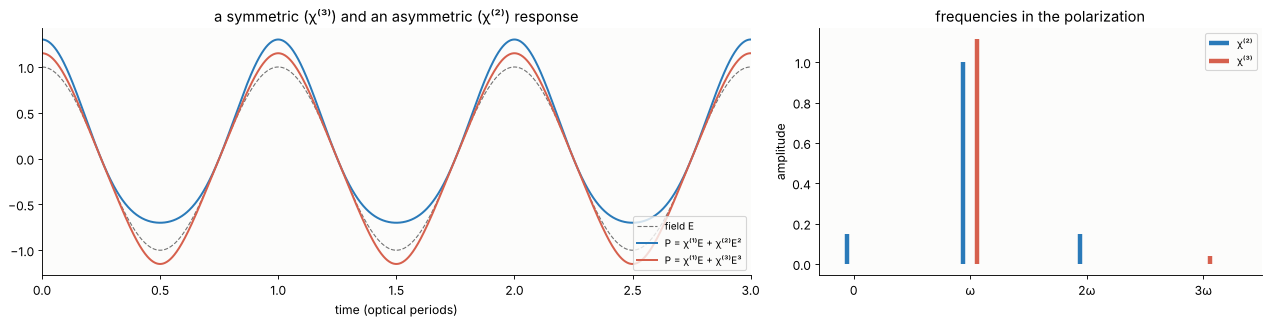

In [2]:
# a field E0 cos(omega t) in a medium with P = eps0 (chi1 E + chi2 E**2 + chi3 E**3)
t = np.linspace(0, 8, 4000, endpoint=False)          # optical periods
E = np.cos(2*np.pi*t)
chi1, chi2, chi3 = 1.0, 0.3, 0.15
P_lin, P2, P3 = chi1*E, chi2*E**2, chi3*E**3
f = np.fft.rfftfreq(len(t), t[1] - t[0])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(t, E, color=GREY, lw=1, ls="--", label="field E")
ax.plot(t, P_lin + P2, color=BLUE, lw=1.8, label="P = χ⁽¹⁾E + χ⁽²⁾E²")
ax.plot(t, P_lin + P3, color=RED, lw=1.8, label="P = χ⁽¹⁾E + χ⁽³⁾E³")
ax.set_xlim(0, 3); ax.set_xlabel("time (optical periods)"); ax.legend(fontsize=9, loc="lower right")
ax.set_title("a symmetric (χ⁽³⁾) and an asymmetric (χ⁽²⁾) response")
ax = axes[1]
for P, c, lab, off in ((P_lin + P2, BLUE, "χ⁽²⁾", -0.06), (P_lin + P3, RED, "χ⁽³⁾", 0.06)):
    S = np.abs(np.fft.rfft(P))/len(t)*2
    S[0] /= 2
    k = np.nonzero(S > 1E-6)[0]
    ax.vlines(f[k] + off, 0, S[k], color=c, lw=4, label=lab)
ax.set_xlim(-0.3, 3.5); ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["0", "ω", "2ω", "3ω"])
ax.set_ylabel("amplitude"); ax.legend(fontsize=9); ax.set_title("frequencies in the polarization")
plt.tight_layout()
plt.show()

## 2. Coupled amplitude equations

With slowly varying amplitudes $a_j$ normalized so that $|a_j|^2$ is the
intensity, the fundamental (1) and the harmonic (2) of a plane wave obey

$$\frac{da_1}{dz} = i\kappa\,a_2a_1^*e^{-i\Delta k z},\qquad
\frac{da_2}{dz} = i\kappa\,a_1^2e^{i\Delta k z},\qquad
\kappa = \omega d_{\rm eff}\sqrt{\frac{2}{n_1^2n_2\varepsilon_0c^3}},$$

with the phase mismatch $\Delta k = 2k_1 - k_2$. Phase matched, the energy
flows completely into the harmonic, $I_2 = I\tanh^2(\kappa\sqrt{I}z)$
(Armstrong et al. 1962); at low conversion the efficiency is

$$\eta = \frac{2\omega^2d_{\rm eff}^2L^2I}{n_1^2n_2\varepsilon_0c^3}\,
\mathrm{sinc}^2\frac{\Delta kL}{2},$$

quadratic in length and linear in intensity. Without phase matching the
harmonic grows only over the **coherence length** $L_c = \pi/|\Delta k|$,
then converts back to the fundamental, and so on. The plots solve the
equations (`NL.shg()`) for a 10 mm crystal with $d_{\rm eff}$ = 2 pm/V
(BBO), and for short distances with mismatch.

BBO, both ordinary: dk = 233 1/mm, coherence length 13.51 µm


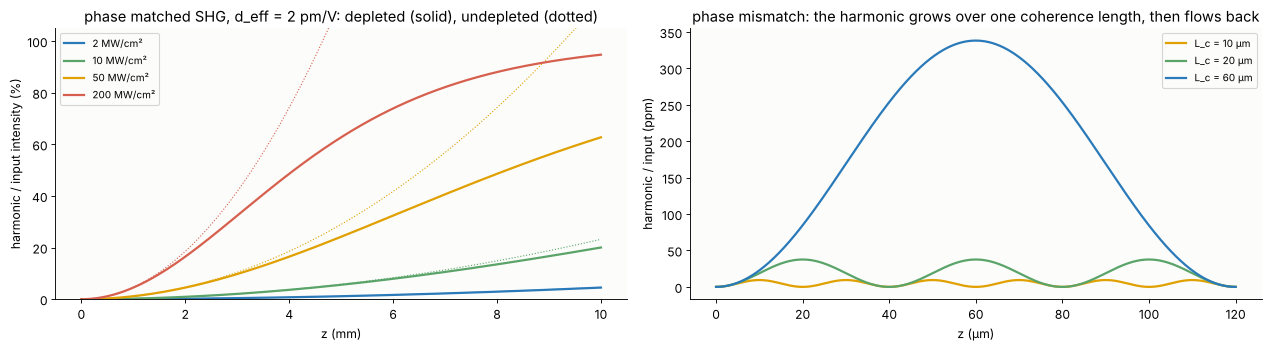

    2 MW/cm²: 10 mm, undepleted     4.6 %, with depletion   4.5 %
   10 MW/cm²: 10 mm, undepleted    23.2 %, with depletion  20.0 %
   50 MW/cm²: 10 mm, undepleted   116.0 %, with depletion  62.7 %
  200 MW/cm²: 10 mm, undepleted   464.1 %, with depletion  94.8 %


In [3]:
lam1 = 1064E-9
n1, n2 = NL.bbo_indices(1064.0)[0], NL.bbo_indices(532.0)[0]   # both ordinary: not phase matched
dk_bbo = NL.delta_k("BBO", 1064.0, theta=0.0, pol="ooo")
print("BBO, both ordinary: dk = {:.3g} 1/mm, coherence length {:.2f} µm".format(
    abs(dk_bbo)*1E-3, NL.coherence_length(dk_bbo)*1E6))

d = 2.0E-12
L = 10E-3
kap = NL.shg_kappa(d, lam1, n1, n1)
z = np.linspace(0, L, 801)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ax = axes[0]
for I_GW, c in ((0.002, BLUE), (0.01, GREEN), (0.05, ORANGE), (0.2, RED)):
    I0 = I_GW*1E13                                # GW/cm² to W/m²
    a1, a2 = NL.shg(z, I0, lam1, n1, n1, d)
    ax.plot(z*1E3, np.abs(a2)**2/I0*100, color=c, lw=2, label=f"{I_GW*1E3:g} MW/cm²")
    ax.plot(z*1E3, NL.shg_efficiency(I0, z, d, lam1, n1, n1)*100, color=c, lw=1, ls=":")
ax.set_ylim(0, 105); ax.set_xlabel("z (mm)"); ax.set_ylabel("harmonic / input intensity (%)")
ax.set_title("phase matched SHG, d_eff = 2 pm/V: depleted (solid), undepleted (dotted)")
ax.legend(fontsize=9)
ax = axes[1]
I0 = 1E13
L_c0 = 20E-6
for m, c in ((0.5, ORANGE), (1.0, GREEN), (3.0, BLUE)):
    dk = np.pi/(m*L_c0)
    zz = np.linspace(0, 120E-6, 1201)
    a1, a2 = NL.shg(zz, I0, lam1, n1, n1, d, dk=dk)
    lab = "L_c = {:.0f} µm".format(NL.coherence_length(dk)*1E6)
    ax.plot(zz*1E6, np.abs(a2)**2/I0*1E6, color=c, lw=2, label=lab)
ax.set_xlabel("z (µm)"); ax.set_ylabel("harmonic / input (ppm)")
ax.set_title("phase mismatch: the harmonic grows over one coherence length, then flows back")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
for I_GW in (0.002, 0.01, 0.05, 0.2):
    print("{:5.0f} MW/cm²: 10 mm, undepleted {:7.1f} %, with depletion {:5.1f} %".format(
        I_GW*1E3, NL.shg_efficiency(I_GW*1E13, L, d, lam1, n1, n1)*100, NL.shg_depleted(I_GW*1E13, L, d, lam1, n1, n1)*100))

Even an intensity of 2 MW/cm² converts 4.5 % in 10 mm of BBO, and
50 MW/cm² (a Q-switched laser of notebook 143 (Q-switching and mode-locking), focused to a millimetre) converts 63 %. The undepleted
formula is good below about 20 %. Without phase matching, BBO with both
waves ordinary has $\Delta k$ = 233 mm⁻¹ and a coherence length of 13.5 µm:
the harmonic oscillates at the ppm level however long the crystal is.

## 3. Birefringent phase matching

In a negative uniaxial crystal ($n_e < n_o$) the extraordinary index of the
harmonic, $n_e(2\omega, \theta)$, depends on the angle $\theta$ between the
wave and the optic axis,

$$\frac{1}{n_e(\theta)^2} = \frac{\cos^2\theta}{n_o^2} + \frac{\sin^2\theta}{n_e^2},$$

and can be made equal to the ordinary index of the fundamental: **type I**
phase matching, o + o → e. In **type II** one fundamental wave is ordinary
and one extraordinary, o + e → e, and the angle is larger. The index
surfaces of the two waves (here sections through the optic axis) cross at
the phase matching direction. `NL.uniaxial_waves()` takes the indices from
the index ellipsoid of the `crystals` module (notebook 138, crystal optics), which also gives the **walk-off**: the extraordinary harmonic's
energy flows at the angle $\rho$ to its wave vector, so that the harmonic
beam slides off the fundamental. The effective coefficient depends on
$\theta$ and on the azimuth $\phi$ of the plane of incidence
($d_{\rm eff} = d_{31}\sin\theta - d_{22}\cos\theta\sin3\phi$ for BBO type
I, $d_{36}\sin\theta\sin2\phi$ for KDP).

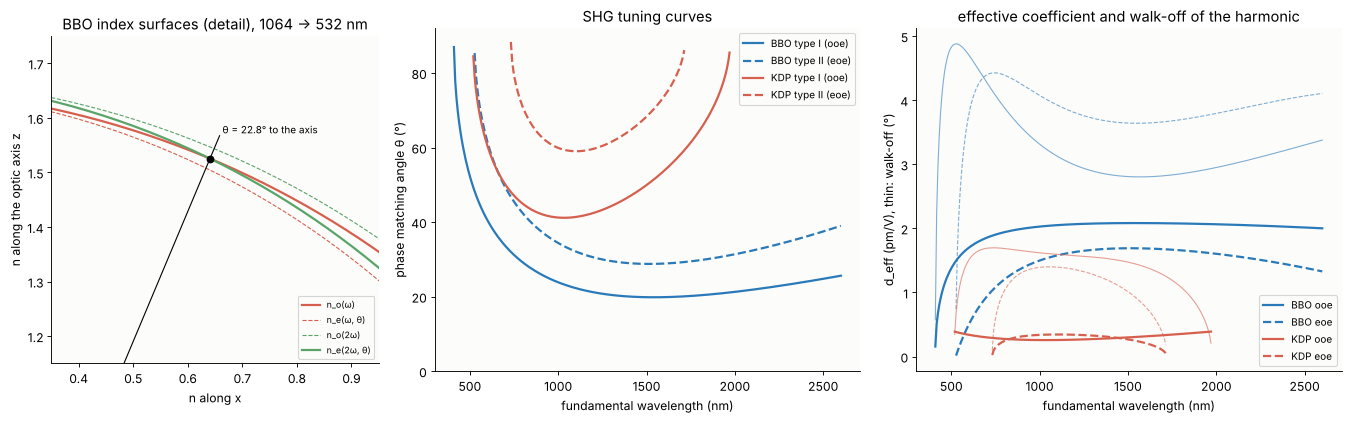

1064 nm SHG              θ (°)   d_eff (pm/V)  walk-off (mrad)
BBO I  (ooe)         22.78    2.044         55.6
BBO II (eoe)         32.84    1.553         69.4
KDP I  (ooe)         41.21    0.257         28.0
KDP II (eoe)         59.13    0.344         24.4


In [4]:
th = np.linspace(0, 2*np.pi, 721)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
ax = axes[0]
no1, ne1 = NL.bbo_indices(1064.0)
no2, ne2 = NL.bbo_indices(532.0)
ax.plot(no1*np.sin(th), no1*np.cos(th), color=RED, lw=2, label="n_o(ω)")
ax.plot(NL.extraordinary_index(no1, ne1, th)*np.sin(th), NL.extraordinary_index(no1, ne1, th)*np.cos(th),
        color=RED, lw=1, ls="--", label="n_e(ω, θ)")
ax.plot(no2*np.sin(th), no2*np.cos(th), color=GREEN, lw=1, ls="--", label="n_o(2ω)")
ax.plot(NL.extraordinary_index(no2, ne2, th)*np.sin(th), NL.extraordinary_index(no2, ne2, th)*np.cos(th),
        color=GREEN, lw=2, label="n_e(2ω, θ)")
th_I = NL.phase_matching_angle("BBO", 1064.0, pol="ooe")
ax.plot([0, 1.7*np.sin(th_I)], [0, 1.7*np.cos(th_I)], color="k", lw=1)
ax.plot(no1*np.sin(th_I), no1*np.cos(th_I), "ko")
ax.text(1.7*np.sin(th_I), 1.7*np.cos(th_I), f" θ = {np.degrees(th_I):.1f}° to the axis", fontsize=9, va="bottom")
ax.set_aspect("equal")
ax.set_xlim(0.35, 0.95); ax.set_ylim(1.15, 1.75)
ax.set_xlabel("n along x"); ax.set_ylabel("n along the optic axis z")
ax.set_title("BBO index surfaces (detail), 1064 → 532 nm"); ax.legend(fontsize=8, loc="lower right")

wl = np.linspace(410, 2600, 300)
ax = axes[1]
for cr, pol, c, ls in (("BBO", "ooe", BLUE, "-"), ("BBO", "eoe", BLUE, "--"),
                       ("KDP", "ooe", RED, "-"), ("KDP", "eoe", RED, "--")):
    ang = np.array([NL.phase_matching_angle(cr, w, pol=pol) for w in wl])
    ax.plot(wl, np.degrees(ang), color=c, ls=ls, lw=2, label=f"{cr} type {'I' if pol == 'ooe' else 'II'} ({pol})")
ax.set_xlabel("fundamental wavelength (nm)"); ax.set_ylabel("phase matching angle θ (°)")
ax.set_title("SHG tuning curves"); ax.legend(fontsize=9); ax.set_ylim(0, 92)
ax = axes[2]
for cr, pol, c, ls, phi in (("BBO", "ooe", BLUE, "-", np.pi/2), ("BBO", "eoe", BLUE, "--", 0.0),
                            ("KDP", "ooe", RED, "-", np.pi/4), ("KDP", "eoe", RED, "--", 0.0)):
    ang = np.array([NL.phase_matching_angle(cr, w, pol=pol) for w in wl])
    ax.plot(wl, NL.d_eff(cr, ang, phi, pol), color=c, ls=ls, lw=2, label=f"{cr} {pol}")
    rho = NL.uniaxial_waves(*NL.indices(cr, wl/2), ang)[2]
    ax.plot(wl, np.degrees(rho), color=c, ls=ls, lw=1, alpha=0.6)
ax.set_xlabel("fundamental wavelength (nm)"); ax.set_ylabel("d_eff (pm/V), thin: walk-off (°)")
ax.set_title("effective coefficient and walk-off of the harmonic"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("1064 nm SHG              θ (°)   d_eff (pm/V)  walk-off (mrad)")
for cr, pol, phi in (("BBO", "ooe", np.pi/2), ("BBO", "eoe", 0.0), ("KDP", "ooe", np.pi/4), ("KDP", "eoe", 0.0)):
    a = NL.phase_matching_angle(cr, 1064.0, pol=pol)
    rho = NL.uniaxial_waves(*NL.indices(cr, 532.0), a)[2]
    print("{} {} ({})        {:6.2f}   {:6.3f}        {:5.1f}".format(cr, "I " if pol == "ooe" else "II", pol,
          np.degrees(a), NL.d_eff(cr, a, phi, pol), rho*1E3))

At 1064 nm, BBO phase matches at 22.8° (type I) and 32.8° (type II), KDP
at 41.2° and 59.1°, the textbook values. BBO has eight times the
$d_{\rm eff}$ of KDP and works down to 410 nm fundamental (205 nm
harmonic), KDP stops near 517 nm. Its price is the walk-off: 56 mrad
(3.2°) in type I, so that a 100 µm beam separates from its harmonic after
2 mm.

## 4. Acceptance bandwidths

A crystal of length $L$ converts efficiently only while
$|\Delta k|L/2 < 1.39$ (half the peak efficiency). Expanding $\Delta k$ in a
parameter $x$ around the phase matched value gives the full width
$5.57/(L\,|\partial\Delta k/\partial x|)$, inversely proportional to the
length. Angle tuned crystals are **critically** phase matched:
$\Delta k$ changes linearly with the angle, and the acceptance is a
fraction of a milliradian. Where the derivative vanishes, the acceptance
grows as $1/\sqrt{L}$ (**noncritical** phase matching): along 90° in a
temperature tuned crystal for the angle, and for the wavelength where the
group velocities of fundamental and harmonic happen to match, as in KDP
at 1064 nm. `NL.acceptance_bandwidth()` finds the half maximum points
numerically.

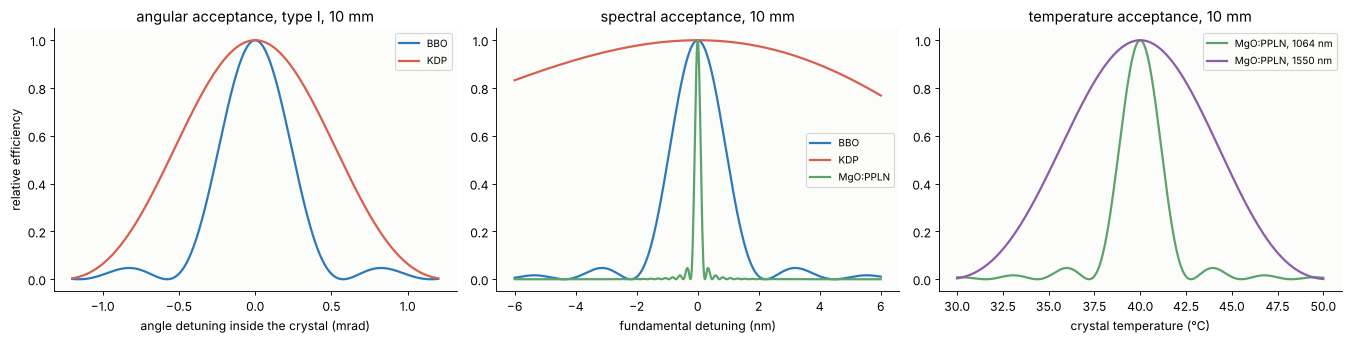

10 mm crystals, FWHM acceptance for 1064 nm SHG
  BBO      angle  0.51 mrad, bandwidth  1.96 nm
  KDP      angle  1.13 mrad, bandwidth 21.98 nm
  MgO:PPLN period 6.95 µm, bandwidth  0.21 nm, temperature 2.47 K
  MgO:PPLN at 1550 nm: period 19.34 µm, bandwidth  1.19 nm, temperature 9.26 K


In [5]:
L4 = 10E-3
th0 = NL.phase_matching_angle("BBO", 1064.0)
d_th = np.linspace(-1.2E-3, 1.2E-3, 801)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]
for cr, c in (("BBO", BLUE), ("KDP", RED)):
    t0 = NL.phase_matching_angle(cr, 1064.0)
    dk = NL.delta_k(cr, 1064.0, theta=t0 + d_th)
    ax.plot(d_th*1E3, np.sinc(dk*L4/(2*np.pi))**2, color=c, lw=2, label=cr)
ax.set_xlabel("angle detuning inside the crystal (mrad)"); ax.set_ylabel("relative efficiency")
ax.set_title("angular acceptance, type I, 10 mm"); ax.legend(fontsize=9)
ax = axes[1]
dwl = np.linspace(-6, 6, 801)
for cr, c in (("BBO", BLUE), ("KDP", RED)):
    t0 = NL.phase_matching_angle(cr, 1064.0)
    dk = NL.delta_k(cr, 1064.0 + dwl, theta=t0)
    ax.plot(dwl, np.sinc(dk*L4/(2*np.pi))**2, color=c, lw=2, label=cr)
P_ln = NL.qpm_period("MgO:LN", 1064.0, T=40)
dk = NL.delta_k("MgO:LN", 1064.0 + dwl, T=40, period=P_ln)
ax.plot(dwl, np.sinc(dk*L4/(2*np.pi))**2, color=GREEN, lw=2, label="MgO:PPLN")
ax.set_xlabel("fundamental detuning (nm)"); ax.set_title("spectral acceptance, 10 mm"); ax.legend(fontsize=9)
ax = axes[2]
TT = np.linspace(30, 50, 801)
dk = NL.delta_k("MgO:LN", 1064.0, T=TT, period=P_ln)
ax.plot(TT, np.sinc(dk*L4/(2*np.pi))**2, color=GREEN, lw=2, label="MgO:PPLN, 1064 nm")
P_15 = NL.qpm_period("MgO:LN", 1550.0, T=40)
dk = NL.delta_k("MgO:LN", 1550.0, T=TT, period=P_15)
ax.plot(TT, np.sinc(dk*L4/(2*np.pi))**2, color=PURPLE, lw=2, label="MgO:PPLN, 1550 nm")
ax.set_xlabel("crystal temperature (°C)"); ax.set_title("temperature acceptance, 10 mm"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("10 mm crystals, FWHM acceptance for 1064 nm SHG")
for cr in ("BBO", "KDP"):
    t0 = NL.phase_matching_angle(cr, 1064.0)
    ang = NL.acceptance_bandwidth(lambda x: NL.delta_k(cr, 1064.0, theta=x), t0, L4)[0]
    spec = NL.acceptance_bandwidth(lambda x: NL.delta_k(cr, x, theta=t0), 1064.0, L4)[0]
    print("  {:8s} angle {:5.2f} mrad, bandwidth {:5.2f} nm".format(cr, ang*1E3, spec))
spec = NL.acceptance_bandwidth(lambda x: NL.delta_k("MgO:LN", x, T=40, period=P_ln), 1064.0, L4)[0]
temp = NL.acceptance_bandwidth(lambda x: NL.delta_k("MgO:LN", 1064.0, T=x, period=P_ln), 40.0, L4)[0]
print("  MgO:PPLN period {:.2f} µm, bandwidth {:5.2f} nm, temperature {:4.2f} K".format(P_ln*1E6, spec, temp))
temp = NL.acceptance_bandwidth(lambda x: NL.delta_k("MgO:LN", 1550.0, T=x, period=P_15), 40.0, L4)[0]
spec = NL.acceptance_bandwidth(lambda x: NL.delta_k("MgO:LN", x, T=40, period=P_15), 1550.0, L4)[0]
print("  MgO:PPLN at 1550 nm: period {:.2f} µm, bandwidth {:5.2f} nm, temperature {:4.2f} K".format(
    P_15*1E6, spec, temp))

For 10 mm crystals:

| 1064 nm SHG | angle (mrad) | bandwidth (nm) | temperature (K) |
|---|---|---|---|
| BBO type I | 0.51 | 1.96 | (small) |
| KDP type I | 1.13 | 22.0 | (small) |
| MgO:PPLN | (noncritical) | 0.21 | 2.5 |

A beam of 1 mm diameter diverges by 1.3 mrad at 1064 nm, more than the
angular acceptance of BBO: tight focusing does not pay in a critically
phase matched crystal (section 6). KDP accepts 22 nm because its group
velocities at 1064 and 532 nm are nearly equal, which makes it a crystal
for doubling broad spectra and short pulses at that wavelength. PPLN
accepts only 0.2 nm and 2.5 K at 1064 nm, more at 1550 nm (1.2 nm,
9.3 K): its strong dispersion is the price of its large coefficient, and
PPLN doublers sit in ovens stabilized to 0.1 K.

## 5. Quasi-phase matching

Instead of matching the indices, the sign of $d$ can be flipped every
coherence length: just when the harmonic would start to flow back, the
reversed nonlinearity turns it around, and the harmonic keeps growing in
a staircase. A ferroelectric crystal such as LiNbO₃ is **periodically
poled** with a high voltage across a patterned electrode, with the
period $\Lambda = 2\pi/|\Delta k|$. All three waves can then be
extraordinary and use the largest coefficient $d_{33}$ (25 pm/V, against
2 pm/V in BBO), there is no walk-off, and the period, not the angle,
selects the wavelengths. The Fourier component of the square wave gives
$d_{\rm eff} = (2/m\pi)\sin(m\pi D)\,d_{33}$ for the order $m$ and the duty
cycle $D$. Here the equations are solved with the actual domain pattern
$d(z)$ over eight periods of MgO:PPLN at 40 °C, with the index of
Gayer et al. (2008).

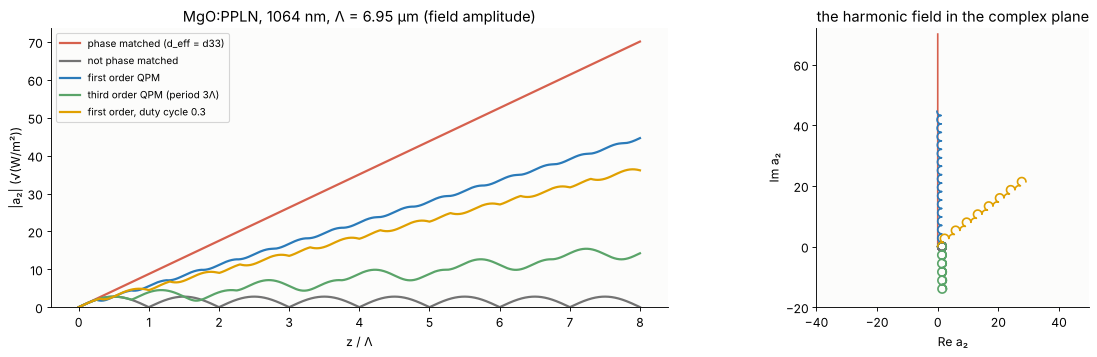

phase matched (d_eff = d33)    |a2|/|a2(PM)| = 1.000
not phase matched              |a2|/|a2(PM)| = 0.000
first order QPM                |a2|/|a2(PM)| = 0.637
third order QPM (period 3Λ)    |a2|/|a2(PM)| = 0.203
first order, duty cycle 0.3    |a2|/|a2(PM)| = 0.515
2/pi = 0.637, 2/(3 pi) = 0.212, (2/pi) sin(0.3 pi) = 0.515


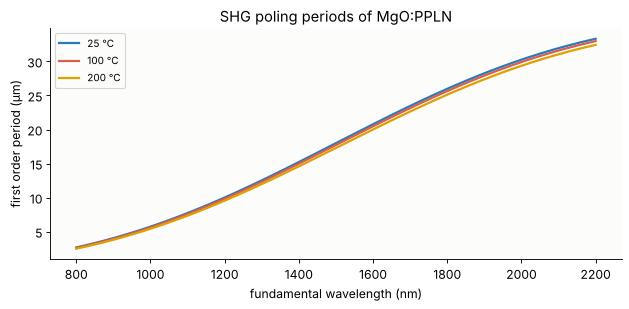

In [6]:
Lam = NL.qpm_period("MgO:LN", 1064.0, T=40)
n1q, n2q = NL.mgo_ln_ne(1064.0, 40), NL.mgo_ln_ne(532.0, 40)
dkq = NL.delta_k("MgO:LN", 1064.0, T=40)
d33 = NL.CRYSTALS["MgO:LN"]["d"]["d33"]*1E-12
I0 = 1E9
zq = np.linspace(0, 8*Lam, 1601)
cases = [("phase matched (d_eff = d33)", d33, 0.0, RED),
         ("not phase matched", d33, dkq, GREY),
         ("first order QPM", lambda z: d33*np.sign(np.cos(2*np.pi*z/Lam)), dkq, BLUE),
         ("third order QPM (period 3Λ)", lambda z: d33*np.sign(np.cos(2*np.pi*z/(3*Lam))), dkq, GREEN),
         ("first order, duty cycle 0.3", lambda z: d33*np.where((z/Lam) % 1 < 0.3, 1.0, -1.0), dkq, ORANGE)]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
res = {}
for name, dd, dk, c in cases:
    a1, a2 = NL.shg(zq, I0, 1064E-9, n1q, n2q, dd, dk=dk, max_step=Lam/60)
    res[name] = a2
    axes[0].plot(zq/Lam, np.abs(a2), color=c, lw=2, label=name)
    axes[1].plot(np.real(a2), np.imag(a2), color=c, lw=1.5)
axes[0].set_xlabel("z / Λ"); axes[0].set_ylabel("|a₂| (√(W/m²))"); axes[0].set_ylim(0, None)
axes[0].set_title(f"MgO:PPLN, 1064 nm, Λ = {Lam*1E6:.2f} µm (field amplitude)")
axes[0].legend(fontsize=9)
axes[1].set_xlabel("Re a₂"); axes[1].set_ylabel("Im a₂"); axes[1].set_aspect("equal")
axes[1].set_xlim(-40, 50); axes[1].set_ylim(-20, 72)
axes[1].set_title("the harmonic field in the complex plane")
plt.tight_layout()
plt.show()
ref = np.abs(res["phase matched (d_eff = d33)"][-1])
for name, *_ in cases:
    print("{:30s} |a2|/|a2(PM)| = {:.3f}".format(name, np.abs(res[name][-1])/ref))
print("2/pi = {:.3f}, 2/(3 pi) = {:.3f}, (2/pi) sin(0.3 pi) = {:.3f}".format(2/np.pi, 2/(3*np.pi), 2/np.pi*np.sin(0.3*np.pi)))

wl = np.linspace(800, 2200, 200)
fig, ax = plt.subplots(figsize=(8, 4))
for T, c in ((25, BLUE), (100, RED), (200, ORANGE)):
    ax.plot(wl, NL.qpm_period("MgO:LN", wl, T=T)*1E6, color=c, lw=2, label=f"{T} °C")
ax.set_xlabel("fundamental wavelength (nm)"); ax.set_ylabel("first order period (µm)")
ax.set_title("SHG poling periods of MgO:PPLN"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The quasi-phase matched harmonic follows the phase matched one with the
ratio $2/\pi$ = 0.637 in field ($0.41$ in power), with the expected
wiggles: in the complex plane it advances in arcs, while the phase
matched field goes straight. Third order poling (a period three times
longer, easier to write) gives 0.20 here, close to $2/3\pi$ = 0.21 (the
short crystal ends in the middle of a period), and a duty cycle of 0.3
loses 19 % of the field. The first order period is 6.95 µm for 1064 nm
and 19.3 µm for 1550 nm; heating shortens it slightly, which is how
PPLN is fine tuned.

## 6. Focused beams: Boyd and Kleinman

A continuous laser needs focusing to reach useful intensities, but a
focus shorter than the crystal wastes length. Boyd and Kleinman (1968)
integrated the harmonic of a Gaussian beam focused in the centre of the
crystal. The harmonic power is

$$P_2 = \frac{16\pi^2d_{\rm eff}^2}{\varepsilon_0c\lambda_1^3n_1n_2}\,L\,P_1^2\,h(\sigma, B, \xi),$$

with the focusing parameter $\xi = L/b$ ($b = 2z_R$ the confocal
parameter), the phase mismatch $\sigma = b\Delta k/2$ and the walk-off
parameter $B = \rho\sqrt{Lk_1}/2$. For weak focusing $h = \xi$ and $P_2$
grows as $L^2/w_0^2$, like a plane wave. Without walk-off the optimum is
$h$ = 1.068 at $\xi$ = 2.84, with a small positive mismatch that
compensates the Gouy phase of the focus; then $P_2$ grows only linearly
with $L$. Walk-off (large $B$) lowers $h$ and the optimum focusing.

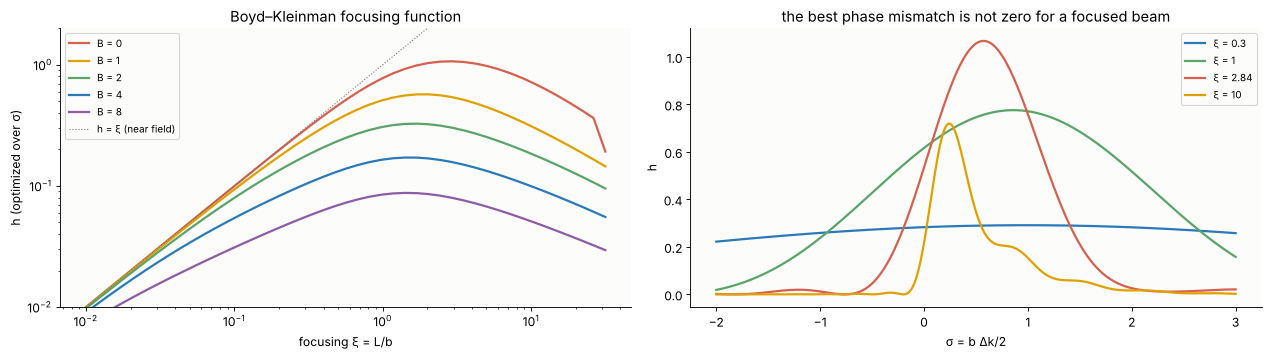

optimum without walk-off: h = 1.068 at xi = 2.84, sigma = 0.57
MgO:PPLN, optimum focus (w0 = 16.6 µm): 27.8 mW, 2.78 %/W


BBO: B = 8.7, best xi = 1.55, h = 0.081: 0.065 mW, 0.0065 %/W


KDP: B = 4.2, best xi = 1.55, h = 0.165: 0.002 mW, 0.0002 %/W


In [7]:
xis = np.logspace(-2, 1.5, 45)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
for B, c in ((0.0, RED), (1.0, ORANGE), (2.0, GREEN), (4.0, BLUE), (8.0, PURPLE)):
    h = np.array([NL.boyd_kleinman_optimum(x, B, n_points=200)[0] for x in xis])
    ax.loglog(xis, h, color=c, lw=2, label=f"B = {B:g}")
ax.loglog(xis, xis, color=GREY, ls=":", lw=1, label="h = ξ (near field)")
ax.set_ylim(1E-2, 2); ax.set_xlabel("focusing ξ = L/b"); ax.set_ylabel("h (optimized over σ)")
ax.set_title("Boyd–Kleinman focusing function"); ax.legend(fontsize=9)
ax = axes[1]
sig = np.linspace(-2, 3, 400)
for x, c in ((0.3, BLUE), (1.0, GREEN), (2.84, RED), (10.0, ORANGE)):
    ax.plot(sig, NL.boyd_kleinman_h(x, sig), color=c, lw=2, label=f"ξ = {x:g}")
ax.set_xlabel("σ = b Δk/2"); ax.set_ylabel("h"); ax.legend(fontsize=9)
ax.set_title("the best phase mismatch is not zero for a focused beam")
plt.tight_layout()
plt.show()
h_opt, s_opt = NL.boyd_kleinman_optimum(2.84)
print("optimum without walk-off: h = {:.3f} at xi = 2.84, sigma = {:.2f}".format(h_opt, s_opt))

# 1 W at 1064 nm, single pass, 10 mm crystals
P1, Lx = 1.0, 10E-3
rows = []
k1 = 2*np.pi*n1q/1064E-9
b_opt = Lx/2.84
w_opt = np.sqrt(b_opt/k1)
P2 = NL.shg_power_focused(P1, Lx, 2/np.pi*d33, 1064E-9, n1q, n2q, h_opt)
print("MgO:PPLN, optimum focus (w0 = {:.1f} µm): {:.1f} mW, {:.2f} %/W".format(w_opt*1E6, P2*1E3, P2/P1**2*100))
for cr, phi in (("BBO", np.pi/2), ("KDP", np.pi/4)):
    a = NL.phase_matching_angle(cr, 1064.0)
    no, ne = NL.indices(cr, 532.0)
    rho = NL.uniaxial_waves(no, ne, a)[2]
    n1c = NL.indices(cr, 1064.0)[0]
    B = rho*np.sqrt(Lx*2*np.pi*n1c/1064E-9)/2
    xi_s = np.logspace(-1, 1.3, 30)
    hs = np.array([NL.boyd_kleinman_optimum(x, B, n_points=300)[0] for x in xi_s])
    i = np.argmax(hs)
    P2 = NL.shg_power_focused(P1, Lx, NL.d_eff(cr, a, phi)*1E-12, 1064E-9, n1c, ne, hs[i])
    print("{}: B = {:.1f}, best xi = {:.2f}, h = {:.3f}: {:.3f} mW, {:.4f} %/W".format(cr, B, xi_s[i], hs[i], P2*1E3,
                                                                                     P2/P1**2*100))

With 1 W at 1064 nm and 10 mm crystals: MgO:PPLN at the optimum focus
($w_0$ = 17 µm) gives 28 mW, 2.8 %/W; BBO, with $B$ = 8.7 and $h$ = 0.08,
gives 0.07 mW, and KDP 0.002 mW. This is why low power continuous lasers
are doubled in periodically poled crystals or inside the laser resonator,
where the circulating power is a hundred times the output (the green
laser pointer has its KTP crystal in the cavity), or in an external
enhancement cavity.

## 7. Doubling femtosecond pulses

A short pulse has a broad spectrum, and its fundamental and harmonic
travel at different group velocities: the **group velocity mismatch**
GVM $= 1/v_{g2} - 1/v_{g1}$ makes the harmonic generated at the front of
the crystal slip behind the fundamental. After the walk-off length
$\tau/\mathrm{GVM}$ the harmonic pulse lengthens, and its spectrum is
limited by the spectral acceptance. The coupled equations for envelopes
in time (`NL.shg_pulse()`, an RK4IP solver of the `splitstep` module) add
GVM and group velocity dispersion,

$$\frac{\partial A_2}{\partial z} = -\mathrm{GVM}\,\frac{\partial A_2}{\partial t}
 - \frac{i\beta_{2,2}}{2}\frac{\partial^2A_2}{\partial t^2} + i\kappa A_1^2,$$

here for 50 fs pulses at 800 nm (a Ti:sapphire laser of notebook 143,
Q-switching and mode-locking) in type I BBO, with the group indices from
the Sellmeier equations (`ultrafast.group_index()`).

BBO type I at 800 nm: theta = 29.2°, group indices 1.6845 and 1.7426
GVM 194 fs/mm, GVD 75 and 196 fs²/mm


 0.1 mm: harmonic   5.0 % of the energy,   37 fs FWHM, peak at   10 fs (GVM L =   19 fs)


 0.5 mm: harmonic  46.0 % of the energy,   74 fs FWHM, peak at   65 fs (GVM L =   97 fs)


 2.0 mm: harmonic  80.1 % of the energy,   89 fs FWHM, peak at  350 fs (GVM L =  388 fs)


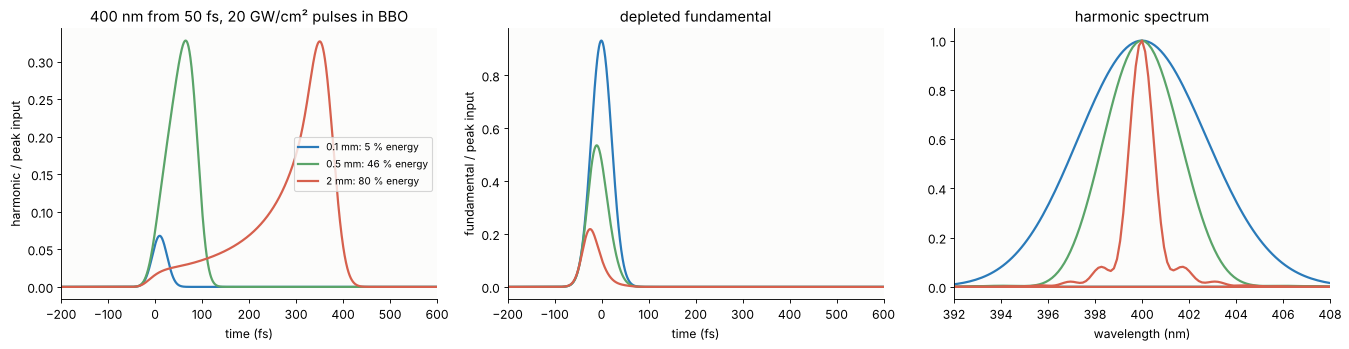

walk-off length: T_fwhm/GVM = 0.26 mm


In [8]:
# group velocities in BBO for 800 nm (type I, o -> e)
th8 = NL.phase_matching_angle("BBO", 800.0)
n_o_f = lambda w: NL.bbo_indices(w)[0]
n_e_th = lambda w: NL.extraordinary_index(*NL.bbo_indices(w), th8)
c_um_fs = 0.299792458
ng1, ng2 = group_index(n_o_f, 800.0), group_index(n_e_th, 400.0)
gvm = (ng2 - ng1)/c_um_fs                        # fs/µm
b2_1, b2_2 = gvd(n_o_f, 800.0), gvd(n_e_th, 400.0)   # fs²/mm
print("BBO type I at 800 nm: theta = {:.1f}°, group indices {:.4f} and {:.4f}".format(np.degrees(th8), ng1, ng2))
print("GVM {:.0f} fs/mm, GVD {:.0f} and {:.0f} fs²/mm".format(gvm*1E3, b2_1, b2_2))

d8 = NL.d_eff("BBO", th8)*1E-12
n1b, n2b = n_o_f(800.0), n_e_th(400.0)
kap8 = NL.shg_kappa(d8, 800E-9, n1b, n2b)*1E-3     # per mm per sqrt(W/m²)
tt = np.linspace(-2000, 2000, 2**13, endpoint=False)
T_fwhm = 50.0
I_pk = 20E13                                        # 20 GW/cm²
A1 = np.sqrt(I_pk)*np.exp(-2*np.log(2)*(tt/T_fwhm)**2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
lengths = (0.1, 0.5, 2.0)
for Lb, c in zip(lengths, (BLUE, GREEN, RED)):
    b1, b2s = NL.shg_pulse(tt, A1, Lb, kap8, gvm=gvm*1E3, beta2=(b2_1, b2_2), steps=400)
    E_in, E_sh = np.sum(np.abs(A1)**2), np.sum(np.abs(b2s)**2)
    axes[0].plot(tt, np.abs(b2s)**2/I_pk, color=c, lw=2, label=f"{Lb:g} mm: {E_sh/E_in*100:.0f} % energy")
    axes[1].plot(tt, np.abs(b1)**2/I_pk, color=c, lw=2)
    Om, S = SS.spectrum(tt, b2s)
    lam_sh = 2*np.pi*c_um_fs*1E3/(2*np.pi*c_um_fs*1E3/400.0 + Om)
    axes[2].plot(lam_sh, np.abs(S)**2/np.max(np.abs(S)**2), color=c, lw=2)
    print("{:4.1f} mm: harmonic {:5.1f} % of the energy, {:4.0f} fs FWHM, peak at {:4.0f} fs (GVM L = {:4.0f} fs)".format(
        Lb, E_sh/E_in*100, fwhm(tt, np.abs(b2s)**2), tt[np.argmax(np.abs(b2s))], gvm*1E3*Lb))
axes[0].set_xlabel("time (fs)"); axes[0].set_ylabel("harmonic / peak input"); axes[0].legend(fontsize=9)
axes[0].set_xlim(-200, 600); axes[1].set_xlim(-200, 600)
axes[0].set_title("400 nm from 50 fs, 20 GW/cm² pulses in BBO")
axes[1].set_xlabel("time (fs)"); axes[1].set_ylabel("fundamental / peak input")
axes[1].set_title("depleted fundamental")
axes[2].set_xlabel("wavelength (nm)"); axes[2].set_xlim(392, 408); axes[2].set_title("harmonic spectrum")
plt.tight_layout()
plt.show()
print("walk-off length: T_fwhm/GVM = {:.2f} mm".format(T_fwhm/(gvm*1E3)))

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 52 s


In BBO at 800 nm the harmonic lags by 194 fs/mm, so the walk-off length of
a 50 fs pulse is 0.26 mm. A 0.1 mm crystal converts 5 % into a 37 fs
harmonic, shorter than the fundamental by $\sqrt{2}$, as the square of a
Gaussian should be. A 0.5 mm crystal converts 46 % of the energy, but the
harmonic stretches to 74 fs and its spectrum narrows. In 2 mm the
conversion reaches 80 %: the harmonic trails the fundamental by 350 fs,
nearly the full walk-off of 390 fs, with a slow front made while the
fundamental was still there and a steep back where it ran out, and its
spectrum is a few nm wide. Thin crystals (tens of µm) for the shortest
pulses, thick ones for efficiency: the usual compromise of ultrafast
frequency conversion.

## Summary

- **χ⁽²⁾** needs crystals without inversion symmetry; it makes $2\omega$,
  $\omega_1 \pm \omega_2$ and optical rectification.
- **Coupled amplitudes:** phase matched SHG converts completely,
  $\tanh^2(\kappa\sqrt{I}L)$; at low conversion $\eta \propto
  d^2L^2I\,\mathrm{sinc}^2(\Delta kL/2)$. Mismatched, the harmonic only grows
  over $L_c = \pi/|\Delta k|$ (13.5 µm in BBO).
- **Birefringent phase matching:** BBO 22.8° (I) and 32.8° (II), KDP
  41.2° and 59.1° at 1064 nm, with walk-off of tens of mrad.
- **Acceptance** $\propto 1/L$: 0.5 mrad and 2 nm for 10 mm BBO; KDP
  accepts 22 nm because its group velocities match.
- **Quasi-phase matching:** $d_{\rm eff} = 2d_{33}/\pi$ with
  $\Lambda$ = 6.95 µm for 1064 nm in MgO:PPLN, no walk-off, any
  wavelength in the transparency range.
- **Focusing:** $h$ = 1.068 at $L/b$ = 2.84; 2.8 %/W in 10 mm PPLN
  against 0.007 %/W in BBO.
- **Pulses:** the group velocity mismatch (194 fs/mm in BBO at 800 nm)
  limits the crystal length for femtosecond pulses.

## References

- R. W. Boyd, *Nonlinear Optics*, 4th ed., Academic Press (2020), chapter 2.
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapter 22.
- J. A. Armstrong, N. Bloembergen, J. Ducuing and P. S. Pershan,
  "Interactions between light waves in a nonlinear dielectric", Phys. Rev.
  127, 1918–1939 (1962).
- G. D. Boyd and D. A. Kleinman, "Parametric interaction of focused
  Gaussian light beams", J. Appl. Phys. 39, 3597–3639 (1968).
- M. M. Fejer, G. A. Magel, D. H. Jundt and R. L. Byer,
  "Quasi-phase-matched second harmonic generation: tuning and
  tolerances", IEEE J. Quantum Electron. 28, 2631–2654 (1992).
- O. Gayer, Z. Sacks, E. Galun and A. Arie, "Temperature and wavelength
  dependent refractive index equations for MgO-doped congruent and
  stoichiometric LiNbO₃", Appl. Phys. B 91, 343–348 (2008).
- D. N. Nikogosyan, *Nonlinear Optical Crystals: A Complete Survey*,
  Springer (2005).
- A. M. Weiner, *Ultrafast Optics*, Wiley (2009), chapter 6.